# ZelaCidade — 02. Classificação do relato do cidadão (NLP)

**Objetivo:** a partir do texto livre ("tem um buraco enorme na frente da escola"), descobrir a categoria de zeladoria para encaminhar o pedido sem que o cidadão precise conhecer a estrutura da Prefeitura.

**Dados (atenção):** os textos são **sintéticos**, escritos pelo grupo, porque a Prefeitura não publica o relato do cidadão. As 12 categorias e parte do vocabulário vêm dos serviços oficiais reais do SP156. Há três conjuntos:

| Conjunto | Uso | Origem |
|---|---|---|
| Treino (A) | treinar e escolher o limiar | frases do grupo A + combinações de vocabulário |
| Teste (B) | avaliação | frases do grupo B, **nunca vistas no treino** |
| Escritas à mão | avaliação final | 36 mensagens em linguagem coloquial, escritas antes de qualquer resultado |

Como os três foram escritos pelo mesmo grupo, os números abaixo **não** garantem o desempenho com relatos reais de cidadãos.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from zela import nlp  # noqa: E402

SINT = RAIZ / "data" / "sintetico"
FIG = RAIZ / "docs" / "evidencias"
treino = pd.read_csv(SINT / "mensagens_treino.csv")
teste = pd.read_csv(SINT / "mensagens_teste.csv")
mao = pd.read_csv(SINT / "mensagens_escritas_a_mao.csv")
print(f"treino {len(treino)} | teste {len(teste)} | escritas à mão {len(mao)} | categorias {treino['categoria'].nunique()}")
treino.sample(5, random_state=1)[["texto", "categoria"]]

treino 1800 | teste 600 | escritas à mão 36 | categorias 12


,texto,categoria
1462,gostaria de reclamar: tem lixo grande abandona...,entulho
510,"PREFEITURA, A FAIXA DE PEDESTRE ESTA APAGADA A...",sinalizacao
612,tem lpaca de trânsito apagada na rua das flore...,sinalizacao
1322,"bom dia, pombos fazendo ninho e sujando tudo a...",pragas
993,"bom dia, caçamba de entulho largada há dias pe...",entulho


## 1. Pré-processamento

1. **Anonimização (LGPD), antes de tudo:** e-mail, CPF e telefone viram marcadores. É o único texto que o sistema grava. O CEP é mantido, porque indica o local do problema e não a pessoa.
2. **Normalização:** minúsculas, sem acento e sem pontuação, para "ÁRVORE caiu!!" e "arvore caiu" virarem o mesmo texto.

In [2]:
exemplo = "BUEIRO sem tampa na Rua X, cep 05409011!! Me liga (11) 98765-4321, CPF 123.456.789-09 ou ana@email.com"
print("original:    ", exemplo)
print("anonimizado: ", nlp.anonimizar(exemplo))
print("normalizado: ", nlp.normalizar(nlp.anonimizar(exemplo)))

original:     BUEIRO sem tampa na Rua X, cep 05409011!! Me liga (11) 98765-4321, CPF 123.456.789-09 ou ana@email.com
anonimizado:  BUEIRO sem tampa na Rua X, cep 05409011!! Me liga [TELEFONE], CPF [CPF] ou [EMAIL]
normalizado:  bueiro sem tampa na rua x cep 05409011 me liga cpf ou


## 2. Representação e modelos

**TF-IDF** com duas visões do texto: palavras e pares de palavras capturam o assunto; pedaços de 3 a 5 caracteres toleram erros de digitação ("bueiro", "boeiro"). Comparamos três modelos usando **validação cruzada agrupada por frase de origem**: cada dobra testa frases que não estavam no treino daquela dobra, o que imita o que vai acontecer com frases novas.

In [3]:
x_treino = treino["texto"].map(nlp.anonimizar)
modelos = {
    "Naive Bayes (palavras)": make_pipeline(TfidfVectorizer(preprocessor=nlp.normalizar, ngram_range=(1, 2), min_df=2), MultinomialNB(alpha=0.3)),
    "Reg. logística (palavras)": make_pipeline(TfidfVectorizer(preprocessor=nlp.normalizar, ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=5, max_iter=2000)),
    "Reg. logística (palavras + caracteres)": nlp.criar_modelo(),
}
cv = GroupKFold(5)
comparacao, oof = [], {}
for nome, modelo in modelos.items():
    proba = cross_val_predict(modelo, x_treino, treino["categoria"], groups=treino["grupo"], cv=cv, method="predict_proba")
    classes = np.array(sorted(treino["categoria"].unique()))
    pred = classes[proba.argmax(1)]
    oof[nome] = (proba, pred)
    comparacao.append({"modelo": nome, "acurácia": accuracy_score(treino["categoria"], pred),
                       "F1 macro": f1_score(treino["categoria"], pred, average="macro")})
pd.DataFrame(comparacao).round(3)

,modelo,acurácia,F1 macro
0,Naive Bayes (palavras),0.636,0.640
1,Reg. logística (palavras),0.709,0.714
2,Reg. logística (palavras + caracteres),0.839,0.839


## 3. Quando o modelo deve pedir ajuda: limiar de triagem humana

Pedidos com confiança abaixo do limiar vão para um atendente em vez de serem encaminhados automaticamente. **Regra definida antes de olhar o teste:** o menor limiar que mantenha pelo menos 90% de acerto nos pedidos automáticos, na validação cruzada agrupada.

Limiar escolhido: 0.30 (constante em src/zela/nlp.py: 0.3)


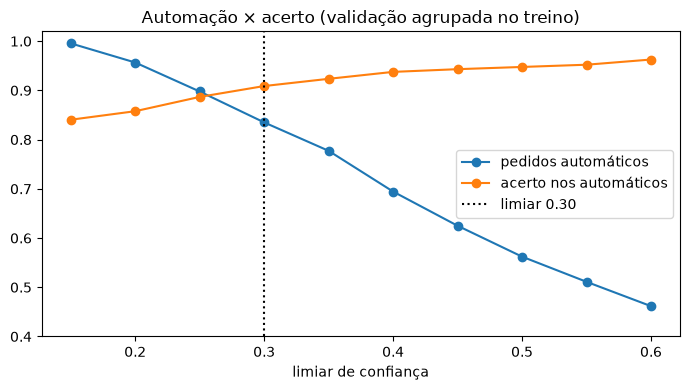

,limiar,automáticos,acerto nos automáticos
0,0.15,0.996,0.840
1,0.20,0.957,0.858
2,0.25,0.898,0.887
3,0.30,0.835,0.909
4,0.35,0.777,0.924
5,0.40,0.694,0.938
6,0.45,0.625,0.943
7,0.50,0.562,0.948
8,0.55,0.511,0.952
9,0.60,0.462,0.963


In [4]:
proba, pred = oof["Reg. logística (palavras + caracteres)"]
conf = proba.max(1)
linhas = []
for lim in np.arange(0.15, 0.61, 0.05):
    ok = conf >= lim
    linhas.append({"limiar": round(lim, 2), "automáticos": ok.mean(), "acerto nos automáticos": accuracy_score(treino["categoria"][ok], pred[ok])})
curva = pd.DataFrame(linhas)
escolhido = curva[curva["acerto nos automáticos"] >= 0.90]["limiar"].min()
print(f"Limiar escolhido: {escolhido:.2f} (constante em src/zela/nlp.py: {nlp.LIMIAR_CONFIANCA})")
assert abs(escolhido - nlp.LIMIAR_CONFIANCA) < 1e-9
fig, eixo = plt.subplots(figsize=(7, 4))
eixo.plot(curva["limiar"], curva["automáticos"], marker="o", label="pedidos automáticos")
eixo.plot(curva["limiar"], curva["acerto nos automáticos"], marker="o", label="acerto nos automáticos")
eixo.axvline(escolhido, color="k", ls=":", label=f"limiar {escolhido:.2f}")
eixo.set(xlabel="limiar de confiança", ylim=(0.4, 1.02), title="Automação × acerto (validação agrupada no treino)")
eixo.legend()
fig.tight_layout()
fig.savefig(FIG / "nlp_limiar.png", dpi=130)
plt.show()
curva.round(3)

## 4. Avaliação final: frases nunca vistas e mensagens escritas à mão

O modelo final é treinado com todo o conjunto A e avaliado uma vez nos conjuntos B e "escritas à mão".

In [5]:
modelo = nlp.criar_modelo().fit(x_treino, treino["categoria"])
resultados = []
for nome, dados in (("Teste B (frases nunca vistas)", teste), ("Escritas à mão", mao)):
    x = dados["texto"].map(nlp.anonimizar)
    p = modelo.predict(x)
    c = modelo.predict_proba(x).max(1)
    ok = c >= nlp.LIMIAR_CONFIANCA
    resultados.append({"conjunto": nome, "n": len(dados), "acurácia geral": accuracy_score(dados["categoria"], p),
                       "F1 macro": f1_score(dados["categoria"], p, average="macro"),
                       "vão para triagem humana": 1 - ok.mean(),
                       "acerto nos automáticos": accuracy_score(dados["categoria"][ok], p[ok]),
                       "erros encaminhados sem revisão": ((p != dados["categoria"]) & ok).mean()})
tabela_final = pd.DataFrame(resultados).round(3)
tabela_final

,conjunto,n,acurácia geral,F1 macro,vão para triagem humana,acerto nos automáticos,erros encaminhados sem revisão
0,Teste B (frases nunca vistas),600,0.690,0.691,0.288,0.785,0.153
1,Escritas à mão,36,0.778,0.786,0.111,0.812,0.167


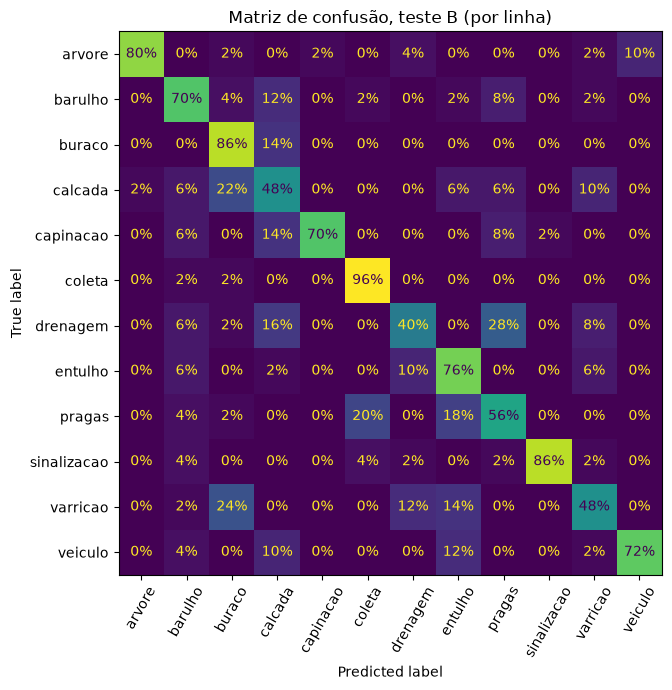

In [6]:
x = teste["texto"].map(nlp.anonimizar)
fig, eixo = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(teste["categoria"], modelo.predict(x), ax=eixo, xticks_rotation=60, colorbar=False, normalize="true", values_format=".0%")
eixo.set_title("Matriz de confusão, teste B (por linha)")
fig.tight_layout()
fig.savefig(FIG / "nlp_confusao.png", dpi=130)
plt.show()

## 5. Onde o modelo erra

Os erros das mensagens escritas à mão mostram os limites reais da abordagem.

In [7]:
x = mao["texto"].map(nlp.anonimizar)
mao_res = mao.assign(previsto=modelo.predict(x), confianca=modelo.predict_proba(x).max(1).round(2))
mao_res["destino"] = np.where(mao_res["confianca"] >= nlp.LIMIAR_CONFIANCA, "automático", "triagem humana")
pd.set_option("display.max_colwidth", 90)
mao_res[mao_res["previsto"] != mao_res["categoria"]][["texto", "categoria", "previsto", "confianca", "destino"]]

,texto,categoria,previsto,confianca,destino
2,"Na descida da ladeira abriram uma vala pra obra e deixaram assim, sem tapar",buraco,entulho,0.60,automático
4,todo domingo aparece um carreto despejando lixo de reforma na praça,entulho,coleta,0.33,automático
5,tem guarda-roupa e sofá rasgado na calçada desde segunda,entulho,calcada,0.42,automático
10,tem um fio da rede elétrica caído no chão perto do ponto de ônibus,calcada,entulho,0.19,triagem humana
12,choveu 10 minutos e a rua virou piscina de novo,drenagem,coleta,0.23,triagem humana
17,terra e pedrisco espalhados pela rua toda depois da chuva,varricao,drenagem,0.32,automático
25,tem um carro de som parado na rua tocando funk alto o domingo inteiro,barulho,veiculo,0.54,automático
29,deixaram uma Kombi velha largada na frente da escola,veiculo,entulho,0.69,automático


**Padrões de erro:**

- **Vocabulário ausente:** gírias e termos que não estavam no treino ("caliça", "carreto", "matagal") puxam o texto para a categoria com palavras mais parecidas.
- **Duas categorias no mesmo relato:** "carro de som" fala de carro e de barulho; "galhos encostando na fiação" fala de árvore e de fiação. O modelo escolhe uma; o relato real tem as duas.
- **Erros confiantes são os perigosos:** os encaminhados sem revisão (última coluna da tabela da seção 4) chegam ao órgão errado. A correção feita pelo atendente no painel fica registrada e pode virar dado de treino real no futuro.

**O limiar não se manteve fora do treino.** Ele foi escolhido para 90% de acerto nos pedidos automáticos, mas nas frases nunca vistas o acerto desses pedidos foi de 78,5%, e 15% de todos os pedidos chegariam ao órgão errado sem revisão. A validação agrupada dentro do treino foi otimista, provavelmente porque frases do mesmo conjunto A compartilham vocabulário e estrutura.

**Conclusão:** o modelo é útil como **triagem assistida**, não como decisão final. Ele acerta a maioria, manda os casos de baixa confiança para um atendente e deixa toda categoria corrigível no painel. Antes de uso real, é preciso: (1) retreinar com relatos reais anonimizados; (2) recalibrar o limiar com esses dados; (3) acompanhar o acerto por categoria a partir das correções feitas pelos atendentes, que o sistema já registra.